# Cats versus Dogs: Transfer Learning

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Classify cat and dog photographs with a pretrained convolutional feature extractor.

**Approach:** InceptionV3-based transfer learning and image augmentation.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 1 Project 5 Cats and Dogs Images
Classification with Deep Learning Technic </span>
    </span>
    </center>
<br>


## Cats and Dogs Images Classification with Deep Learning Technic
### GUERBOUZ MOHAMMED ALAA EDDINE

# Import the Packages

In [ ]:
import os
import zipfile
import shutil
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from google.colab import files
import matplotlib.pyplot as plt
%matplotlib inline

# Download the Dataset

In [ ]:
!wget --no-check-certificate https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip -O /tmp/cats_and_dogs_filtered.zip

--2019-12-11 20:36:44--  https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.204.128, 2404:6800:4008:c06::80
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.204.128|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 68606236 (65M) [application/zip]
Saving to: ‘/tmp/cats_and_dogs_filtered.zip’

/tmp/cats_and_dogs_ 100%[===================>]  65.43M  27.7MB/s    in 2.4s    

2019-12-11 20:36:47 (27.7 MB/s) - ‘/tmp/cats_and_dogs_filtered.zip’ saved [68606236/68606236]



# Extract the Images Dataset

In [ ]:
local_zip = '/tmp/cats_and_dogs_filtered.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/tmp')
zip_ref.close()

# Setup the Images Directories

In [ ]:
base_dir = '/tmp/cats_and_dogs_filtered'
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')

# Configure the Inception V3 Model

## Download the weights of the Model

In [ ]:
!wget --no-check-certificate https://storage.googleapis.com/mledu-datasets/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5 -O /tmp/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5

--2019-12-11 20:36:53--  https://storage.googleapis.com/mledu-datasets/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5
Resolving storage.googleapis.com (storage.googleapis.com)... 64.233.187.128, 2404:6800:4008:c00::80
Connecting to storage.googleapis.com (storage.googleapis.com)|64.233.187.128|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 87910968 (84M) [application/x-hdf]
Saving to: ‘/tmp/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5’

/tmp/inception_v3_w 100%[===================>]  83.84M  69.2MB/s    in 1.2s    

2019-12-11 20:36:54 (69.2 MB/s) - ‘/tmp/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5’ saved [87910968/87910968]



## Configure the Inception V3 Model

In [ ]:
local_weights_file = '/tmp/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5'

In [ ]:
pre_trained_model = InceptionV3(input_shape=(150, 150, 3), include_top=False, weights=None)

Instructions for updating:
If using Keras pass *_constraint arguments to layers.


In [ ]:
pre_trained_model.load_weights(local_weights_file)

In [ ]:
pre_trained_model.summary()

Model: "inception_v3"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 150, 150, 3) 0                                            
__________________________________________________________________________________________________
conv2d (Conv2D)                 (None, 74, 74, 32)   864         input_1[0][0]                    
__________________________________________________________________________________________________
batch_normalization (BatchNorma (None, 74, 74, 32)   96          conv2d[0][0]                     
__________________________________________________________________________________________________
activation (Activation)         (None, 74, 74, 32)   0           batch_normalization[0][0]        
_______________________________________________________________________________________

In [ ]:
# Freeze the Layers
for layer in pre_trained_model.layers:
  layer.trainable = False

In [ ]:
# Retrieve the last layer
last_layer = pre_trained_model.get_layer(name='mixed7')
print('Last Layer Output Shape: ', last_layer.output_shape)

Last Layer Output Shape:  (None, 7, 7, 768)


In [ ]:
# Output of the last layer
last_output = last_layer.output

## Setup the Model

In [ ]:
x = layers.Flatten()(last_output)

x = layers.Dense(units=1024, activation='relu')(x)

x = layers.Dropout(rate=0.2)(x)

x = layers.Dense(units=1, activation='sigmoid')(x)

In [ ]:
model = Model(pre_trained_model.input, x)

In [ ]:
model.compile(optimizer=RMSprop(learning_rate=0.0001), loss='binary_crossentropy', metrics=['acc'])

Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where


# Configure the ImageDataGenerator

In [ ]:
train_datagen = ImageDataGenerator(rescale=1/255, 
                                   rotation_range=40, 
                                   width_shift_range=0.2, 
                                   height_shift_range=0.2, 
                                   shear_range=0.2, 
                                   zoom_range=0.2, 
                                   horizontal_flip=True)

test_datagen = ImageDataGenerator(rescale=1/255)

In [ ]:
train_generator = train_datagen.flow_from_directory(directory=train_dir, target_size=(150, 150), batch_size=20, class_mode='binary')

test_generator = test_datagen.flow_from_directory(directory=validation_dir, target_size=(150, 150), batch_size=20, class_mode='binary')

Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


# Train the model

In [ ]:
history = model.fit_generator(generator=train_generator, steps_per_epoch=100, epochs=20, validation_data=test_generator, validation_steps=50, verbose=1)

Epoch 1/20
100/100 [==============================] - 28s 285ms/step - loss: 0.5167 - acc: 0.7400 - val_loss: 0.2385 - val_acc: 0.9280
Epoch 2/20
100/100 [==============================] - 23s 227ms/step - loss: 0.3869 - acc: 0.8170 - val_loss: 0.2047 - val_acc: 0.9470
Epoch 3/20
100/100 [==============================] - 23s 229ms/step - loss: 0.3384 - acc: 0.8555 - val_loss: 0.3632 - val_acc: 0.9210
Epoch 4/20
100/100 [==============================] - 23s 228ms/step - loss: 0.3199 - acc: 0.8660 - val_loss: 0.4668 - val_acc: 0.9220
Epoch 5/20
100/100 [==============================] - 23s 227ms/step - loss: 0.3354 - acc: 0.8575 - val_loss: 0.3892 - val_acc: 0.9370
Epoch 6/20
100/100 [==============================] - 22s 224ms/step - loss: 0.3107 - acc: 0.8780 - val_loss: 0.2792 - val_acc: 0.9500
Epoch 7/20
100/100 [==============================] - 23s 229ms/step - loss: 0.2882 - acc: 0.8850 - val_loss: 0.2945 - val_acc: 0.9550
Epoch 8/20
100/100 [==============================] - 2

# Evaluating Accuracy and Loss

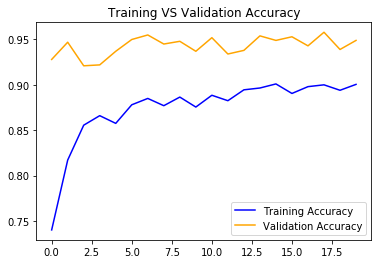

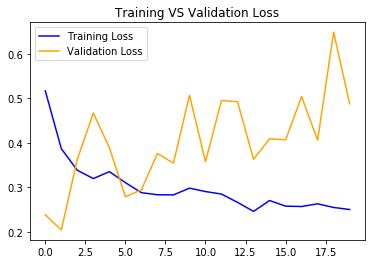

In [ ]:
acc = history.history['acc']
val_acc = history.history['val_acc']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, color='blue', label='Training Accuracy')
plt.plot(epochs, val_acc, color='orange', label='Validation Accuracy')
plt.title('Training VS Validation Accuracy')
plt.legend()
plt.show()

plt.plot(epochs, loss, color='blue', label='Training Loss')
plt.plot(epochs, val_loss, color='orange', label='Validation Loss')
plt.title('Training VS Validation Loss')
plt.legend()
plt.show()

# Test the model on new images [Use google colab]

In [ ]:
class_names = ['Cat', 'Dog']

<b>Note</b> : <i>You might have to run the below cell twice.</i>

Saving dog_5.jpeg to dog_5 (1).jpeg


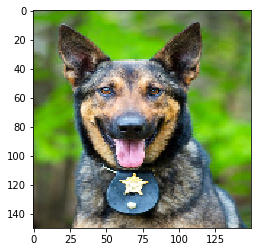

Prediction: Dog


In [ ]:
uploaded = files.upload()

for file_name in uploaded.keys():

  path = file_name

  img = image.load_img(path, target_size=(150, 150))

  x = image.img_to_array(img)

  x = np.expand_dims(x, axis=0)

  x /= 255.

  images = np.vstack([x])

  classes = model.predict(images, batch_size=10)

  plt.imshow(img)
  plt.grid(False)
  plt.show()

  if classes[0][0] > 0.6:
    print('Prediction: {}'.format(class_names[1]))
  else:
    print('Prediction: {}'.format(class_names[0]))

# Save the model

In [ ]:
export_dir = "./saved_model_v1"
tf.saved_model.save(model, export_dir)

# Create a zip file to download the model locally

In [ ]:
shutil.make_archive(base_name="saved_model_v1",format="zip",root_dir="saved_model_v1")

'/content/saved_model_v1.zip'

# Load the saved model


In [ ]:
keras_model = tf.keras.models.load_model(export_dir)

Saving dog_4.jpeg to dog_4 (4).jpeg


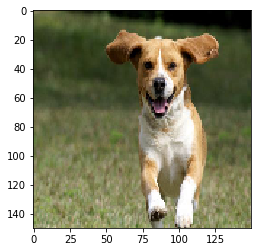

Prediction: Dog


In [ ]:
uploaded = files.upload()

for file_name in uploaded.keys():

  path = file_name

  img = image.load_img(path, target_size=(150, 150))

  x = image.img_to_array(img)

  x = np.expand_dims(x, axis=0)

  x /= 255.

  images = np.vstack([x])

  classes = keras_model.predict(images, batch_size=10)

  plt.imshow(img)
  plt.grid(False)
  plt.show()

  if classes[0][0] > 0.6:
    print('Prediction: {}'.format(class_names[1]))
  else:
    print('Prediction: {}'.format(class_names[0]))